In [17]:
import pandas as pd

In [18]:
# Load dataset
df = pd.read_csv("Phishing_Email.csv")
df

,Unnamed: 0,Email Text,Email Type
0,0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,1,the other side of * galicismos * * galicismo *...,Safe Email
2,2,re : equistar deal tickets are you still avail...,Safe Email
3,3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,4,software at incredibly low prices ( 86 % lower...,Phishing Email
...,...,...,...
18645,18646,date a lonely housewife always wanted to date ...,Phishing Email
18646,18647,request submitted : access request for anita ....,Safe Email
18647,18648,"re : important - prc mtg hi dorn & john , as y...",Safe Email
18648,18649,press clippings - letter on californian utilit...,Safe Email


In [19]:
# 1. Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"])

# 2. Handle missing values
df["Email Text"] = df["Email Text"].fillna("")

# 3. Remove leading and trailing spaces
df["Email Text"] = df["Email Text"].str.strip()

In [20]:
# 4. Remove empty emails
df = df[df["Email Text"] != ""]

# 5. Remove records containing only 'empty'
df = df[df["Email Text"].str.lower() != "empty"]

In [21]:
# 6. Remove duplicate emails
df = df.drop_duplicates(subset=["Email Text"])

# 7. Reset index
df = df.reset_index(drop=True)

In [22]:
# Final dataset information
print(df.shape)
print(df.isnull().sum())
print(df["Email Type"].value_counts())

# Save cleaned dataset
df.to_csv("Cleaned_Phishing_Email.csv", index=False)

(17521, 2)
Email Text    0
Email Type    0
dtype: int64
Email Type
Safe Email        10978
Phishing Email     6543
Name: count, dtype: int64


In [25]:
import os
print(os.getcwd())

C:\Users\santh


In [23]:
df
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17521 entries, 0 to 17520
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Email Text  17521 non-null  object
 1   Email Type  17521 non-null  object
dtypes: object(2)
memory usage: 273.9+ KB


In [24]:
df.head(50)

,Email Text,Email Type
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,the other side of * galicismos * * galicismo *...,Safe Email
2,re : equistar deal tickets are you still avail...,Safe Email
3,Hello I am your hot lil horny toy.\n I am t...,Phishing Email
4,software at incredibly low prices ( 86 % lower...,Phishing Email
5,global risk management operations sally congra...,Safe Email
6,"On Sun, Aug 11, 2002 at 11:17:47AM +0100, wint...",Safe Email
7,"entourage , stockmogul newsletter ralph velez ...",Phishing Email
8,"we owe you lots of money dear applicant , afte...",Phishing Email
9,re : coastal deal - with exxon participation u...,Safe Email


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

Email Type
Safe Email        10978
Phishing Email     6543
Name: count, dtype: int64


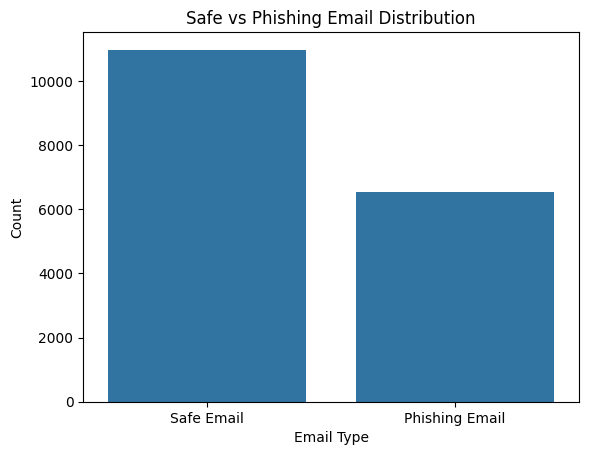

In [29]:
print(df["Email Type"].value_counts())

sns.countplot(data=df, x="Email Type")

plt.title("Safe vs Phishing Email Distribution")
plt.xlabel("Email Type")
plt.ylabel("Count")
plt.show()

# 1. Import libraries

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 2. Load cleaned dataset

In [34]:
df = pd.read_csv("Cleaned_Phishing_Email.csv")
print(df.head())

                                          Email Text      Email Type
0  re : 6 . 1100 , disc : uniformitarianism , re ...      Safe Email
1  the other side of * galicismos * * galicismo *...      Safe Email
2  re : equistar deal tickets are you still avail...      Safe Email
3  Hello I am your hot lil horny toy.\n    I am t...  Phishing Email
4  software at incredibly low prices ( 86 % lower...  Phishing Email


# 3. Separate input and output

In [35]:
x = df["Email Text"]
y = df["Email Type"]

# 4. Train-test split

In [36]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Apply CountVectorizer

In [37]:
cv = CountVectorizer(stop_words="english", max_features=10000)

x_train = cv.fit_transform(x_train)

x_test = cv.transform(x_test)

# Step 6: Train the model

In [38]:
model = MultinomialNB()

model.fit(x_train, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


# Step 7: Make predictions

In [48]:
y_pred = model.predict(x_test)
print("predicted output : ",y_pred[:10])
print("actual output : ",y_test.tolist()[:10])

predicted output :  ['Safe Email' 'Safe Email' 'Safe Email' 'Phishing Email' 'Safe Email'
 'Safe Email' 'Safe Email' 'Phishing Email' 'Phishing Email' 'Safe Email']
actual output :  ['Safe Email', 'Safe Email', 'Safe Email', 'Phishing Email', 'Safe Email', 'Safe Email', 'Safe Email', 'Phishing Email', 'Phishing Email', 'Safe Email']


# 8. Model evaluation

In [49]:
acc = accuracy_score(y_test, y_pred)

print("Accuracy:", acc)

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

Accuracy: 0.969472182596291
                precision    recall  f1-score   support

Phishing Email       0.97      0.95      0.96      1309
    Safe Email       0.97      0.98      0.98      2196

      accuracy                           0.97      3505
     macro avg       0.97      0.96      0.97      3505
  weighted avg       0.97      0.97      0.97      3505

[[1240   69]
 [  38 2158]]



First row: Actual Phishing Email | 
Second row: Actual Safe Email | 
First column: Predicted Phishing Email | 
Second column: Predicted Safe Email | 

1,240
True Positive
Phishing correctly detected

69
False Negative
Phishing missed

38
False Positive
Safe marked as phishing


2,158
True Negative
Safe correctly detected

# 9. Predict a new email

In [51]:
new_email = ["Congratulations! You won a free prize. Click here to claim it."]

new_email = cv.transform(new_email)

prediction = model.predict(new_email)

print("Email Type:", prediction[0])

Email Type: Phishing Email


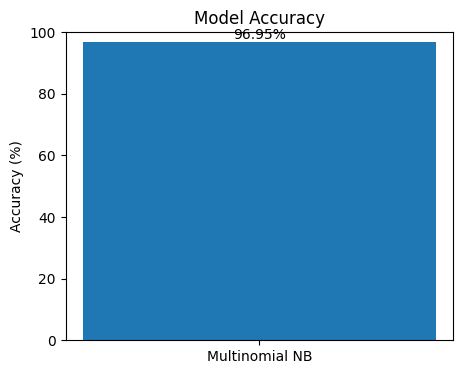

In [52]:
acc = accuracy_score(y_test, y_pred)

plt.figure(figsize=(5,4))

plt.bar(["Multinomial NB"], [acc * 100])

plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy")

plt.text(0, acc * 100 + 1, f"{acc*100:.2f}%", ha="center")

plt.show()